# Postcards from my jungle: training a diffusion model for imagined animals

CART 498 · Assignment 5 · Dan Truong

This notebook trains a small diffusion model **from scratch** on photos of real animals, then generates **50 fictional animals** for my jungle.
It is based on the class notebook *W05-02 Train your own diffuser* (same UNet, cosine noise schedule, EMA weights and training in steps).
What I added: a function that trains one configuration, so I can run several **experiments** (dataset size, image resolution, training length) and compare them before the final run.

**Runtime → Change runtime type → GPU** before running.

## 0. Setup

In [1]:
# Colab sometimes ships a torchao version that breaks diffusers (same fix as the class notebook)
try:
    from diffusers import UNet2DModel
    print("diffusers is ready ✓")
except Exception:
    print("Fixing a package conflict, the session will restart. Run this cell again after.")
    import subprocess, os
    subprocess.run(["pip", "uninstall", "-y", "torchao"])
    os.kill(os.getpid(), 9)

diffusers is ready ✓


In [2]:
import math, os, random, time
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from IPython.display import display

device = "cuda" if torch.cuda.is_available() else "cpu"
gpu = torch.cuda.get_device_name(0) if device == "cuda" else "CPU"
FAST_GPU = any(name in gpu for name in ["A100", "H100", "L4", "G4"])
print("Running on:", gpu, "(fast)" if FAST_GPU else "")

torch.manual_seed(0); random.seed(0)

Running on: Tesla T4 


## 1. Datasets

* **AFHQv2** (`huggan/AFHQv2`): close-up faces of real animals. I keep the **wild** animals (fox, tiger, lion, wolf, leopard…) and the **cats**, and leave out the dogs.
  Faces are centred and similar, which a small model learns well, and big eyes + fur are a good start for cute creatures.
* **Smithsonian butterflies** (`huggan/smithsonian_butterflies_subset`), the class default dataset: I mix some in so the creatures pick up wing shapes and colours, for a fairy feel.

AFHQv2 is large, so it is **streamed**: only the images I use are downloaded.

In [3]:
from datasets import load_dataset

MAX_ANIMALS = 4000      # AFHQv2 images to keep (cats + wild)
MAX_BUTTERFLIES = 800

def square(img, size):
    """Centre-crop to a square and resize (not stretched), as in the class notebook."""
    img = img.convert("RGB")
    w, h = img.size
    s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))
    return img.resize((size, size), Image.LANCZOS)

afhq = load_dataset("huggan/AFHQv2", split="train", streaming=True)
try:
    names = afhq.features["label"].names
except Exception:                       # streamed datasets don't always report their features
    names = ["cat", "dog", "wild"]
keep = {names.index(n) for n in ("cat", "wild") if n in names}
print("AFHQv2 classes:", names, "→ keeping", [names[k] for k in keep])

animals, kinds = [], []
for row in afhq:
    if row["label"] in keep:
        animals.append(square(row["image"], 128))      # stored at 128 px, resized again for each experiment
        kinds.append(names[row["label"]])
        if len(animals) >= MAX_ANIMALS:
            break

butterflies_ds = load_dataset("huggan/smithsonian_butterflies_subset", split="train")
butterflies = [square(r["image"], 128) for r in butterflies_ds.select(range(min(MAX_BUTTERFLIES, len(butterflies_ds))))]

print(f"{len(animals)} animal faces ({kinds.count('cat')} cats, {kinds.count('wild')} wild), {len(butterflies)} butterflies")

dataset_infos.json:   0%|          | 0.00/827 [00:00<?, ?B/s]

AFHQv2 classes: ['cat', 'dog', 'wild'] → keeping ['cat', 'wild']


README.md:   0%|          | 0.00/609 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/1.65k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  237MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

4000 animal faces (0 cats, 4000 wild), 800 butterflies


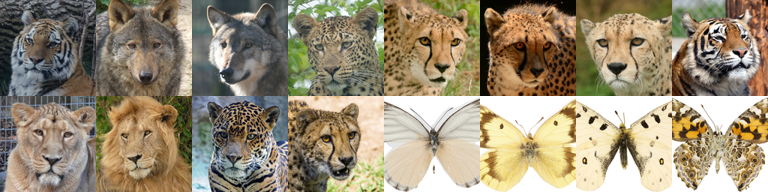

In [4]:
from diffusers.utils import make_image_grid
random.seed(1)
preview = random.sample(animals, 12) + random.sample(butterflies, 4)
display(make_image_grid([im.resize((96, 96)) for im in preview], rows=2, cols=8))

## 2. Training one configuration

`train(...)` does everything for one experiment: resize the images, build the UNet, add noise, learn to predict it, keep EMA weights.
The data sits on the GPU as one tensor, so each step just picks a random batch (faster than a DataLoader for small images).

In [5]:
from diffusers import UNet2DModel, DDPMScheduler
from diffusers.training_utils import EMAModel
from diffusers.optimization import get_cosine_schedule_with_warmup

def to_tensor(images, size):
    """List of PIL images → tensor in [-1, 1], shape (N, 3, size, size)."""
    arr = torch.stack([torch.from_numpy(np.array(im.resize((size, size), Image.LANCZOS))) for im in images])
    return (arr.permute(0, 3, 1, 2).float() / 127.5 - 1.0)

def make_model(size):
    if size <= 32:
        channels = (64, 128, 256)
        down = ("DownBlock2D", "AttnDownBlock2D", "DownBlock2D")
        up = ("UpBlock2D", "AttnUpBlock2D", "UpBlock2D")
    else:
        channels = (64, 128, 256, 256)
        down = ("DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "DownBlock2D")
        up = ("UpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D")
    return UNet2DModel(sample_size=size, in_channels=3, out_channels=3, layers_per_block=2,
                       block_out_channels=channels, down_block_types=down, up_block_types=up).to(device)

def make_scheduler():
    return DDPMScheduler(num_train_timesteps=1000, beta_schedule="squaredcos_cap_v2")

@torch.no_grad()
def generate(model, size, n=16, steps=100, seed=0):
    scheduler = make_scheduler()
    scheduler.set_timesteps(steps)
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn((n, 3, size, size), generator=g, device=device)
    model.eval()
    for t in scheduler.timesteps:
        with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
            noise_pred = model(x, t).sample
        x = scheduler.step(noise_pred.float(), t, x, generator=g).prev_sample
    return x.clamp(-1, 1)

def to_pil(batch, upscale=None):
    out = []
    for img in batch:
        arr = ((img.permute(1, 2, 0).cpu() + 1) * 127.5).round().clamp(0, 255).byte().numpy()
        im = Image.fromarray(arr)
        out.append(im.resize((upscale, upscale), Image.LANCZOS) if upscale else im)
    return out

def train(images, size, steps, batch_size=64, lr=2e-4, model=None, ema=None, label=""):
    data = to_tensor(images, size).to(device)
    if model is None:
        model = make_model(size)
        ema = EMAModel(model.parameters(), decay=0.999, use_ema_warmup=True)
    scheduler = make_scheduler()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    lr_schedule = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=min(500, steps // 10), num_training_steps=steps)
    scaler = torch.amp.GradScaler(enabled=device == "cuda")
    losses, start = [], time.time()
    model.train()
    for step in range(steps):
        idx = torch.randint(0, len(data), (batch_size,), device=device)
        clean = data[idx]
        flip = torch.rand(batch_size, device=device) < 0.5            # random horizontal flip
        clean = torch.where(flip[:, None, None, None], clean.flip(3), clean)
        noise = torch.randn_like(clean)
        t = torch.randint(0, 1000, (batch_size,), device=device)
        noisy = scheduler.add_noise(clean, noise, t)
        with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
            loss = F.mse_loss(model(noisy, t).sample.float(), noise)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); lr_schedule.step()
        ema.step(model.parameters())
        losses.append(loss.item())
        if (step + 1) % max(steps // 5, 1) == 0:
            print(f"{label} step {step + 1}/{steps}  loss {sum(losses[-200:]) / len(losses[-200:]):.4f}  ({(time.time() - start) / 60:.1f} min)")
    return model, ema, losses, (time.time() - start) / 60

def ema_samples(model, ema, size, n=16, seed=0):
    ema.store(model.parameters()); ema.copy_to(model.parameters())
    samples = generate(model, size, n=n, seed=seed)
    ema.restore(model.parameters())
    return samples

@torch.no_grad()
def copying_score(samples, images, size):
    """Mean pixel distance from each generated image to its nearest training image (class notebook, section 10).
    Small = the model is copying its training images."""
    ref = to_tensor(images[:2000], size).to(device)
    d = torch.cdist(samples.flatten(1).float(), ref.flatten(1))
    return d.min(dim=1).values.mean().item() / math.sqrt(3 * size * size)

## 3. Experiments

One change at a time, as suggested in the class notebook (section 11). Each run prints its loss, shows 16 samples (EMA weights) and a **copying score**:
the average distance between each generated image and the closest training image. A very low score means the model is copying rather than inventing.

| | resolution | images | steps | question |
|---|---|---|---|---|
| A | 32 px | 1,000 animals | short | Is a tiny, fast model already enough to read as "animals"? |
| B | 64 px | 150 animals | medium | What happens with a very small dataset? (copying?) |
| C | 64 px | 4,000 animals + 800 butterflies | medium | Does more data, mixed with wings, give more varied, fairy-like creatures? |

In [6]:
STEPS_SHORT = 1500 if FAST_GPU else 1000
STEPS_MEDIUM = 4000 if FAST_GPU else 2500

results = []
def report(name, size, n_images, steps, minutes, losses, samples, images):
    score = copying_score(samples, images, size)
    results.append({"experiment": name, "resolution": f"{size} px", "images": n_images, "steps": steps,
                    "minutes": round(minutes, 1), "final loss": round(sum(losses[-200:]) / 200, 4),
                    "copying score": round(score, 3)})
    display(make_image_grid(to_pil(samples, upscale=96), rows=2, cols=8))
    print(results[-1])

A step 200/1000  loss 0.2879  (0.6 min)
A step 400/1000  loss 0.1123  (1.2 min)
A step 600/1000  loss 0.1052  (1.8 min)
A step 800/1000  loss 0.0972  (2.4 min)
A step 1000/1000  loss 0.0962  (3.0 min)


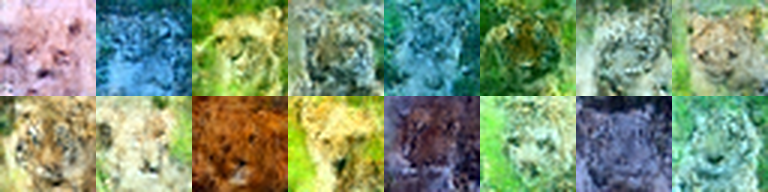

{'experiment': 'A', 'resolution': '32 px', 'images': 1000, 'steps': 1000, 'minutes': 3.0, 'final loss': 0.0962, 'copying score': 0.417}


In [7]:
# Experiment A: 32 px, 1,000 animal faces, short training
imgs_A = animals[:1000]
model_A, ema_A, loss_A, min_A = train(imgs_A, 32, STEPS_SHORT, label="A")
report("A", 32, len(imgs_A), STEPS_SHORT, min_A, loss_A, ema_samples(model_A, ema_A, 32), imgs_A)
del model_A, ema_A; torch.cuda.empty_cache()

In [10]:
# Measured on the free T4: 32 px trains at ~330 steps/min, but 64 px only at ~160 steps/min.
# So experiments B and C are shortened to 1,200 steps; the long training goes to the final model instead.
STEPS_MEDIUM = 1200
print("Experiments B and C:", STEPS_MEDIUM, "steps each")

Experiments B and C: 1200 steps each


B step 240/1200  loss 0.1394  (2.2 min)
B step 480/1200  loss 0.0902  (4.3 min)
B step 720/1200  loss 0.0794  (6.5 min)
B step 960/1200  loss 0.0764  (8.6 min)
B step 1200/1200  loss 0.0720  (10.8 min)


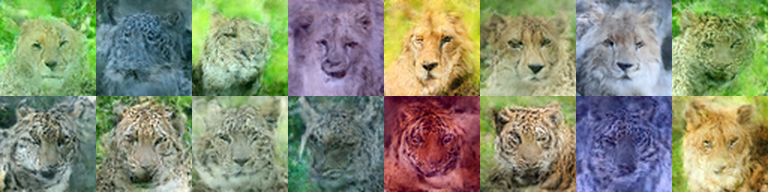

{'experiment': 'B', 'resolution': '64 px', 'images': 150, 'steps': 1200, 'minutes': 10.8, 'final loss': 0.072, 'copying score': 0.41}
Top: generated / nearest training image, side by side


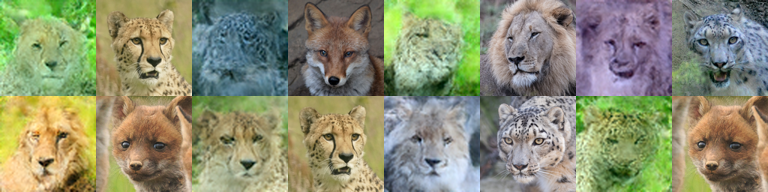

In [11]:
# Experiment B: 64 px, only 150 animal faces
imgs_B = animals[:150]
model_B, ema_B, loss_B, min_B = train(imgs_B, 64, STEPS_MEDIUM, label="B")
samples_B = ema_samples(model_B, ema_B, 64)
report("B", 64, len(imgs_B), STEPS_MEDIUM, min_B, loss_B, samples_B, imgs_B)

# Show each sample next to its nearest training image, like section 10 of the class notebook
ref_B = to_tensor(imgs_B, 64).to(device)
nearest = torch.cdist(samples_B[:8].flatten(1).float(), ref_B.flatten(1)).argmin(1)
pairs = []
for s, i in zip(samples_B[:8], nearest):
    pairs += [to_pil(s[None], upscale=96)[0], imgs_B[i].resize((96, 96))]
print("Top: generated / nearest training image, side by side")
display(make_image_grid(pairs, rows=2, cols=8))
del model_B, ema_B; torch.cuda.empty_cache()

C step 240/1200  loss 0.1445  (2.2 min)
C step 480/1200  loss 0.0891  (4.3 min)
C step 720/1200  loss 0.0799  (6.5 min)
C step 960/1200  loss 0.0783  (8.6 min)
C step 1200/1200  loss 0.0764  (10.8 min)


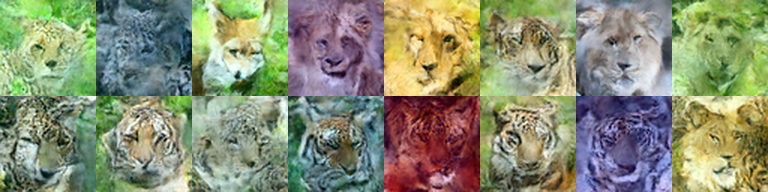

{'experiment': 'C', 'resolution': '64 px', 'images': 4800, 'steps': 1200, 'minutes': 10.8, 'final loss': 0.0764, 'copying score': 0.404}


In [12]:
# Experiment C: 64 px, all animal faces + butterflies
imgs_C = animals + butterflies
random.shuffle(imgs_C)
model_C, ema_C, loss_C, min_C = train(imgs_C, 64, STEPS_MEDIUM, label="C")
report("C", 64, len(imgs_C), STEPS_MEDIUM, min_C, loss_C, ema_samples(model_C, ema_C, 64), imgs_C)

In [13]:
import pandas as pd
pd.DataFrame(results)

,experiment,resolution,images,steps,minutes,final loss,copying score
0,A,32 px,1000,1000,3.0,0.0962,0.417
1,B,64 px,150,1200,10.8,0.0720,0.410
2,C,64 px,4800,1200,10.8,0.0764,0.404


## 4. Final model

The final model **continues training experiment C** (same weights and EMA) for many more steps, instead of starting again from zero.
Quality keeps improving after the loss curve looks flat, as the class notebook points out.

final step 1200/6000  loss 0.0683  (10.8 min)
final step 2400/6000  loss 0.0652  (21.6 min)
final step 3600/6000  loss 0.0645  (32.3 min)
final step 4800/6000  loss 0.0623  (43.1 min)
final step 6000/6000  loss 0.0601  (53.9 min)


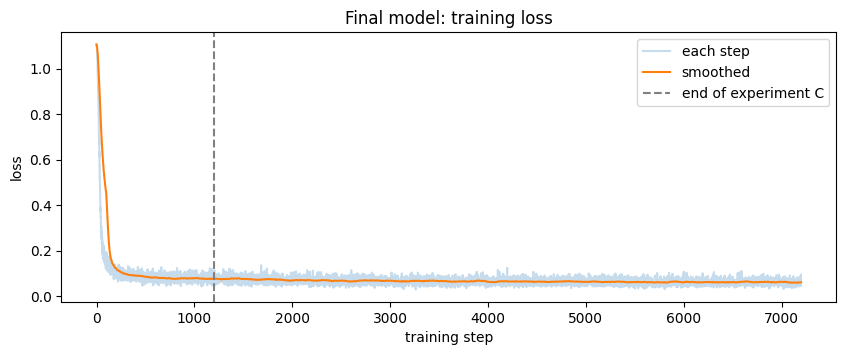

In [14]:
FINAL_EXTRA_STEPS = 12000 if FAST_GPU else 6000
model, ema, loss_final, min_final = train(imgs_C, 64, FINAL_EXTRA_STEPS, model=model_C, ema=ema_C, label="final")
all_losses = loss_C + loss_final

import matplotlib.pyplot as plt
def smooth(v, k=100):
    return [sum(v[max(0, i - k):i + 1]) / len(v[max(0, i - k):i + 1]) for i in range(len(v))]
plt.figure(figsize=(10, 3.5))
plt.plot(all_losses, alpha=0.25, label="each step")
plt.plot(smooth(all_losses), label="smoothed")
plt.axvline(len(loss_C), color="gray", linestyle="--", label="end of experiment C")
plt.xlabel("training step"); plt.ylabel("loss"); plt.title("Final model: training loss"); plt.legend(); plt.show()

ema.copy_to(model.parameters())          # use the smoother EMA weights from now on
torch.save(model.state_dict(), "jungle_ema.pth")

## 5. Generate 50 imagined animals

The model works at 64×64. Each image is upscaled to 256×256 (Lanczos) for the website, so the blurry, painterly, lo-fi look stays.

50 images saved in images/


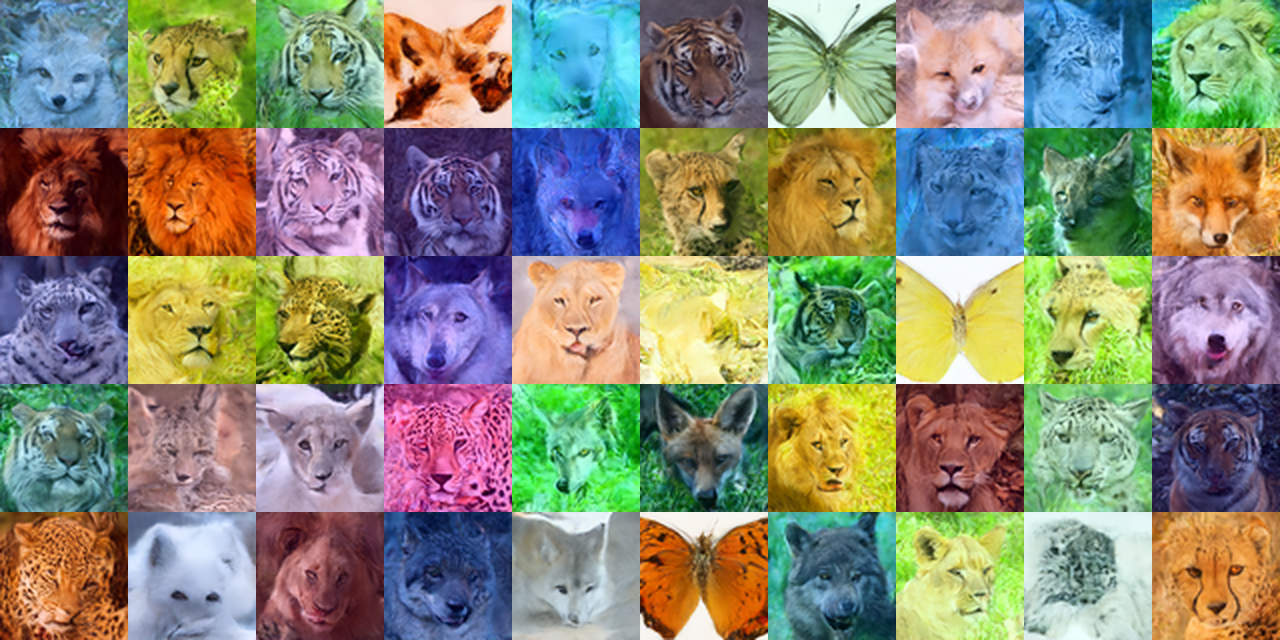

,experiment,resolution,images,steps,minutes,final loss,copying score
0,A,32 px,1000,1000,3.0,0.0962,0.417
1,B,64 px,150,1200,10.8,0.0720,0.410
2,C,64 px,4800,1200,10.8,0.0764,0.404
3,final,64 px,4800,7200,64.6,0.0601,0.420


In [15]:
final_samples = torch.cat([generate(model, 64, n=25, seed=s) for s in (7, 8)])
os.makedirs("images", exist_ok=True)
final_images = to_pil(final_samples, upscale=256)
for i, im in enumerate(final_images, start=1):
    im.save(f"images/beast_{i:02d}.png")
print(len(os.listdir("images")), "images saved in images/")
display(make_image_grid([im.resize((128, 128)) for im in final_images], rows=5, cols=10))

score = copying_score(final_samples, imgs_C, 64)
results.append({"experiment": "final", "resolution": "64 px", "images": len(imgs_C), "steps": len(all_losses),
                "minutes": round(min_C + min_final, 1), "final loss": round(sum(all_losses[-200:]) / 200, 4),
                "copying score": round(score, 3)})
pd.DataFrame(results)

## 6. Download

Zips the 50 images (and this notebook with all its outputs) so they can go in the GitHub repository.

In [ ]:
import json, zipfile
from google.colab import files, _message

# Save this notebook, with its outputs, into the zip as well
nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
with open("image-generation.ipynb", "w") as f:
    json.dump(nb, f)

with zipfile.ZipFile("jungle_images.zip", "w") as z:
    for name in sorted(os.listdir("images")):
        z.write(f"images/{name}")
    z.write("image-generation.ipynb")
print(round(os.path.getsize("jungle_images.zip") / 1e6, 1), "MB")
files.download("jungle_images.zip")